# Serbian Text Classification — Analysis

Companion to `report.md`. Reads the artifacts under `results/` and
`runs/` and produces the plots and tables the prose refers to. Re-run
with **Kernel → Restart & Run All** after any new sweep.

In [1]:
#Imports, paths, and shared style / palette.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
RUNS = ROOT / "runs"

summary = json.loads((RESULTS / "summary.json").read_text(encoding="utf-8"))
dataset_summary = json.loads((RESULTS / "dataset_summary.json").read_text(encoding="utf-8"))

LABEL_NAMES = ["negative", "neutral", "positive"]
MODEL_ORDER = ["xlmr", "bertic"]
MODEL_COLORS = {"xlmr": "#3f88c5", "bertic": "#e94e4e", "baseline": "#888888"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

#Show full comment text in dataframe rows.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

print("Loaded summary.json and dataset_summary.json")

Loaded summary.json and dataset_summary.json


## 1. Dataset overview

SentiComments.SR after cleanup: **3,460 comments**, split 80/10/10
stratified on the final 3-way polarity.

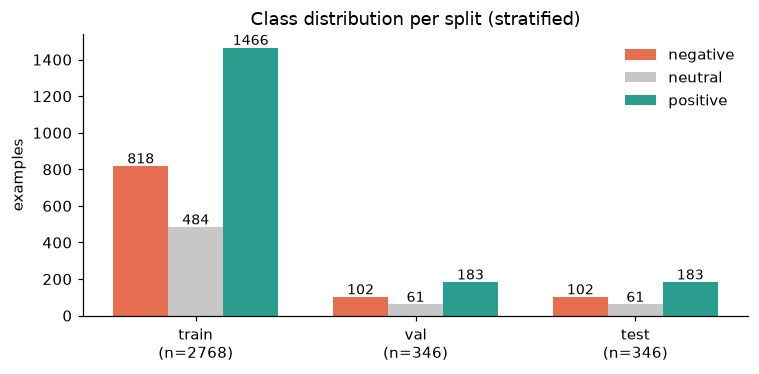

In [2]:
#Class distribution per split — confirms stratification preserved the balance.
splits = ["train", "val", "test"]
counts = np.array([[dataset_summary["splits"][s]["class_counts"][c] for c in LABEL_NAMES] for s in splits])

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(splits))
width = 0.25
colors = ["#e76f51", "#c7c7c7", "#2a9d8f"]
for i, (lbl, color) in enumerate(zip(LABEL_NAMES, colors)):
    bars = ax.bar(x + (i - 1) * width, counts[:, i], width, label=lbl, color=color)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 15,
                int(bar.get_height()), ha="center", fontsize=9)
ax.set_xticks(x, [f"{s}\n(n={dataset_summary['splits'][s]['n_examples']})" for s in splits])
ax.set_ylabel("examples")
ax.set_title("Class distribution per split (stratified)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

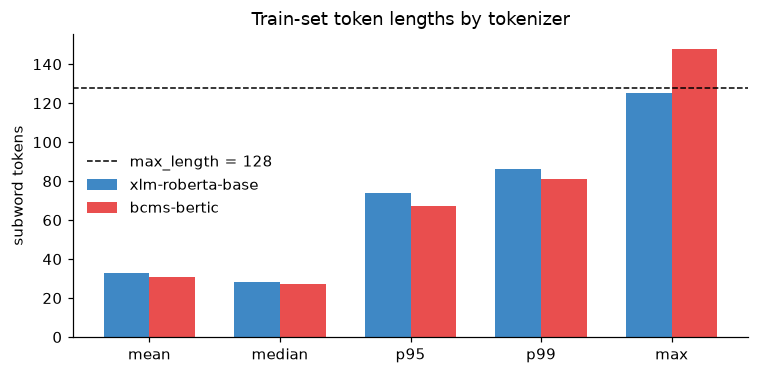

Only 2 training comments exceed 128 tokens under BERTić's tokenizer.


In [3]:
#Token lengths per tokenizer — the data behind the max_length=128 choice.
fig, ax = plt.subplots(figsize=(7, 3.5))
width = 0.35
tokenizers = ["xlm-roberta-base", "bcms-bertic"]
for i, tok in enumerate(tokenizers):
    stats = dataset_summary["splits"]["train"]["token_lens"][tok]
    xs = ["mean", "median", "p95", "p99", "max"]
    ys = [stats[k] for k in xs]
    ax.bar(np.arange(len(xs)) + (i - 0.5) * width, ys, width, label=tok,
           color=MODEL_COLORS["xlmr" if i == 0 else "bertic"])
ax.axhline(128, color="black", linestyle="--", linewidth=1, label="max_length = 128")
ax.set_xticks(np.arange(len(xs)), xs)
ax.set_ylabel("subword tokens")
ax.set_title("Train-set token lengths by tokenizer")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Only {dataset_summary['splits']['train']['token_lens']['bcms-bertic']['n_over_128']} training comments exceed 128 tokens under BERTić's tokenizer.")

## 2. Headline results

Baseline vs each transformer, mean ± std over 3 seeds. The
transformers' error bars are drawn at ±1 std from the mean.

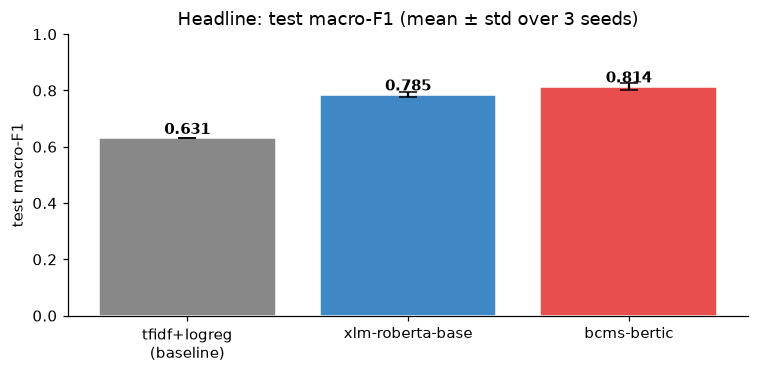

In [4]:
#Headline bar chart: test macro-F1 for baseline + both transformers, with std bars.
labels, f1_means, f1_stds, colors = [], [], [], []
labels.append("tfidf+logreg\n(baseline)")
f1_means.append(summary["baseline"]["test_f1_macro"])
f1_stds.append(0.0)
colors.append(MODEL_COLORS["baseline"])
for key in MODEL_ORDER:
    m = summary["models"][key]
    labels.append(m["model_name"].split("/")[-1])
    f1_means.append(m["test_f1_macro"]["mean"])
    f1_stds.append(m["test_f1_macro"]["std"])
    colors.append(MODEL_COLORS[key])

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(labels, f1_means, yerr=f1_stds, color=colors, capsize=6, edgecolor="white")
for bar, mean in zip(bars, f1_means):
    ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.015, f"{mean:.3f}",
            ha="center", fontsize=10, fontweight="bold")
ax.set_ylabel("test macro-F1")
ax.set_ylim(0, 1.0)
ax.set_title("Headline: test macro-F1 (mean ± std over 3 seeds)")
plt.tight_layout()
plt.show()

In [5]:
#Same numbers as a DataFrame for exact-value reading.
rows = [{
    "model": "tfidf+logreg (baseline)",
    "params (M)": "<0.1",
    "test accuracy": f"{summary['baseline']['test_accuracy']:.4f}",
    "test macro-F1": f"{summary['baseline']['test_f1_macro']:.4f}",
    "train time (s)": "<1",
}]
for key in MODEL_ORDER:
    m = summary["models"][key]
    rows.append({
        "model": m["model_name"],
        "params (M)": f"{m['n_params'] / 1e6:.0f}",
        "test accuracy": f"{m['test_accuracy']['mean']:.4f} ± {m['test_accuracy']['std']:.4f}",
        "test macro-F1": f"{m['test_f1_macro']['mean']:.4f} ± {m['test_f1_macro']['std']:.4f}",
        "train time (s)": f"{m['train_time_s_mean']:.0f}",
    })
pd.DataFrame(rows).set_index("model")

,params (M),test accuracy,test macro-F1,train time (s)
model,,,,
tfidf+logreg (baseline),<0.1,0.6590,0.6307,<1
xlm-roberta-base,278,0.8054 ± 0.0073,0.7851 ± 0.0077,109
classla/bcms-bertic,111,0.8324 ± 0.0126,0.8137 ± 0.0131,65


## 3. Training curves

Per-epoch validation macro-F1 at the chosen LR (seed 42 run — the other
seeds track it closely). Shows how fast each model converges.

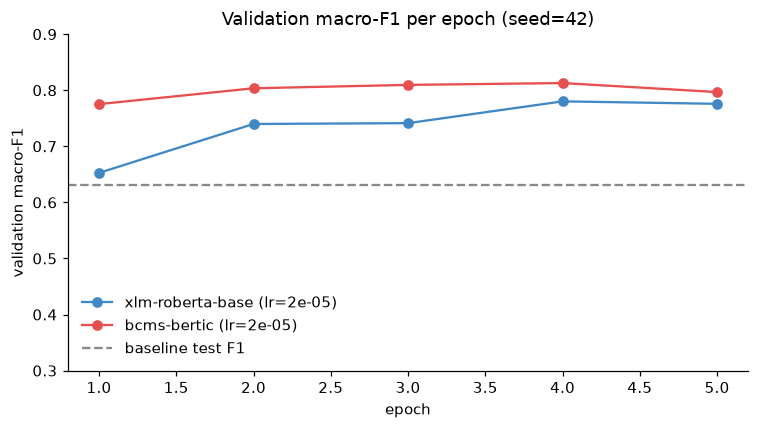

In [6]:
#Val F1 per epoch, seed=42 — shows convergence speed.
fig, ax = plt.subplots(figsize=(7, 4))
for key in MODEL_ORDER:
    m = summary["models"][key]
    lr = m["best_lr"]
    history = json.loads((RUNS / key / f"lr{lr}_seed42" / "metrics.json").read_text(encoding="utf-8"))["val_history"]
    epochs, f1s = [], []
    for e in history:
        if "eval_f1_macro" in e:
            epochs.append(e["epoch"])
            f1s.append(e["eval_f1_macro"])
    ax.plot(epochs, f1s, marker="o", label=f"{m['model_name'].split('/')[-1]} (lr={lr})", color=MODEL_COLORS[key])
ax.axhline(summary["baseline"]["test_f1_macro"], color=MODEL_COLORS["baseline"], linestyle="--", label="baseline test F1")
ax.set_xlabel("epoch")
ax.set_ylabel("validation macro-F1")
ax.set_title("Validation macro-F1 per epoch (seed=42)")
ax.set_ylim(0.3, 0.9)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. Confusion matrices

Seed-42 test predictions. Rows are true labels, columns are predicted.
A model that only ever said "positive" would have one filled column.

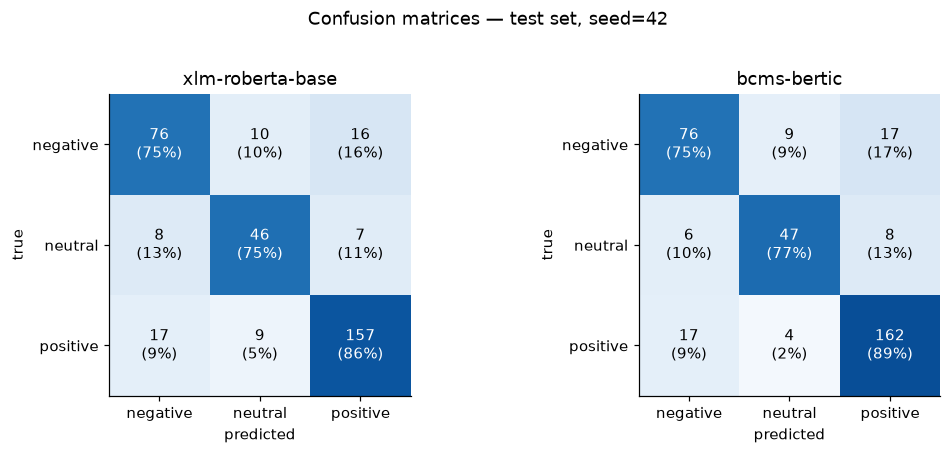

In [7]:
#Normalised confusion matrices (row-sum=1), seed=42.
def _confmat(df):
    cm = np.zeros((3, 3), dtype=int)
    for _, r in df.iterrows():
        cm[int(r["label"]), int(r["pred_label"])] += 1
    return cm

preds = {}
for key in MODEL_ORDER:
    lr = summary["models"][key]["best_lr"]
    preds[key] = pd.read_csv(RUNS / key / f"lr{lr}_seed42" / "test_predictions.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key in zip(axes, MODEL_ORDER):
    cm = _confmat(preds[key])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            color = "white" if cm_norm[i, j] > 0.5 else "black"
            ax.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.0%})",
                    ha="center", va="center", color=color, fontsize=10)
    ax.set_xticks(range(3), LABEL_NAMES)
    ax.set_yticks(range(3), LABEL_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(summary["models"][key]["model_name"].split("/")[-1])
fig.suptitle("Confusion matrices — test set, seed=42", y=1.02)
plt.tight_layout()
plt.show()

## 5. Per-class F1

The baseline leaves neutral and negative weak. Where do the transformers
pull ahead the most?

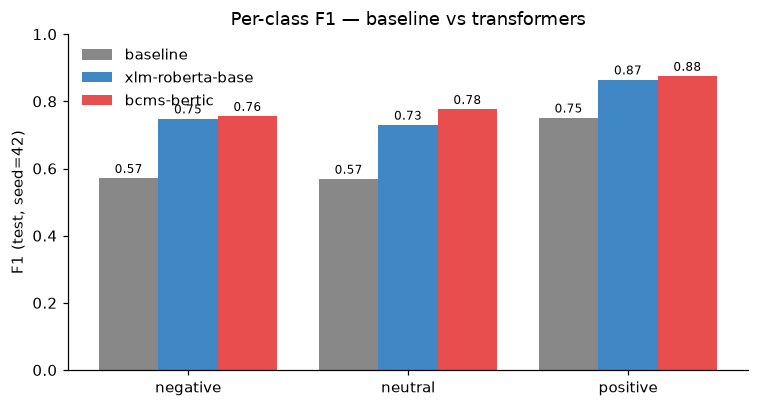

In [8]:
#Per-class F1: where the transformer gains over the baseline are concentrated.
baseline_pc = json.loads((RESULTS / "baseline.json").read_text(encoding="utf-8"))["per_class"]
bertic_pc = json.loads((RUNS / "bertic" / f"lr{summary['models']['bertic']['best_lr']}_seed42" / "metrics.json").read_text(encoding="utf-8"))["per_class"]
xlmr_pc = json.loads((RUNS / "xlmr" / f"lr{summary['models']['xlmr']['best_lr']}_seed42" / "metrics.json").read_text(encoding="utf-8"))["per_class"]

per_class = {
    "baseline": [baseline_pc[c]["f1-score"] for c in LABEL_NAMES],
    "xlm-roberta-base": [xlmr_pc[c]["f1-score"] for c in LABEL_NAMES],
    "bcms-bertic": [bertic_pc[c]["f1-score"] for c in LABEL_NAMES],
}

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(LABEL_NAMES))
width = 0.27
for i, (name, vals) in enumerate(per_class.items()):
    color = MODEL_COLORS["baseline"] if name == "baseline" else MODEL_COLORS["xlmr" if "roberta" in name else "bertic"]
    bars = ax.bar(x + (i - 1) * width, vals, width, label=name, color=color)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.2f}",
                ha="center", fontsize=8)
ax.set_xticks(x, LABEL_NAMES)
ax.set_ylabel("F1 (test, seed=42)")
ax.set_ylim(0, 1.0)
ax.set_title("Per-class F1 — baseline vs transformers")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Model disagreement

How often does each model get it right where the other doesn't? Cases
where both are wrong are the hardest or mislabeled examples.

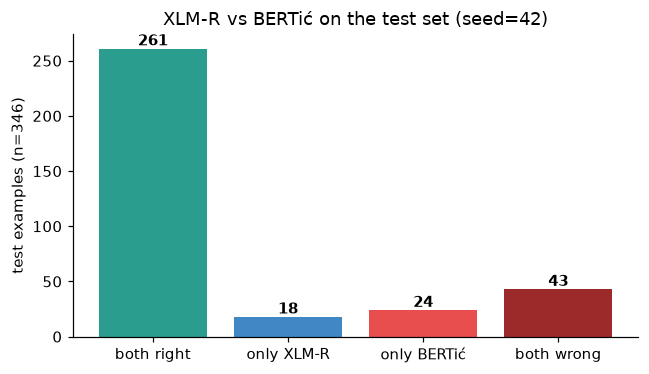

In [9]:
#Agreement breakdown: how often does each model get it right where the other doesn't.
m = preds["xlmr"].merge(preds["bertic"], on=["comment_id", "text", "label", "polarity"], suffixes=("_x", "_b"))
both_right = ((m.pred_label_x == m.label) & (m.pred_label_b == m.label)).sum()
only_xlmr = ((m.pred_label_x == m.label) & (m.pred_label_b != m.label)).sum()
only_bertic = ((m.pred_label_x != m.label) & (m.pred_label_b == m.label)).sum()
both_wrong = ((m.pred_label_x != m.label) & (m.pred_label_b != m.label)).sum()

fig, ax = plt.subplots(figsize=(6, 3.5))
cats = ["both right", "only XLM-R", "only BERTić", "both wrong"]
counts = [both_right, only_xlmr, only_bertic, both_wrong]
colors_bar = ["#2a9d8f", MODEL_COLORS["xlmr"], MODEL_COLORS["bertic"], "#9d2a2a"]
bars = ax.bar(cats, counts, color=colors_bar)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f"{c}", ha="center", fontsize=10, fontweight="bold")
ax.set_ylabel(f"test examples (n={len(m)})")
ax.set_title("XLM-R vs BERTić on the test set (seed=42)")
plt.tight_layout()
plt.show()

In [10]:
#A few named examples of each disagreement case — fuel for the report's prose.
def _rows(df, n=3):
    return df.head(n)[["polarity", "pred_polarity_x", "pred_polarity_b", "text"]].rename(
        columns={"polarity": "true", "pred_polarity_x": "xlmr", "pred_polarity_b": "bertic"}
    )

print("Only BERTić right")
display(_rows(m[(m.pred_label_x != m.label) & (m.pred_label_b == m.label)]))
print("\nOnly XLM-R right")
display(_rows(m[(m.pred_label_x == m.label) & (m.pred_label_b != m.label)]))
print("\nBoth wrong (hardest or mislabeled)")
display(_rows(m[(m.pred_label_x != m.label) & (m.pred_label_b != m.label)], n=5))

Only BERTić right


,true,xlmr,bertic,text
17,positive,negative,positive,filmčina! greh je ako Mads ne dobije Oskara.
25,neutral,positive,neutral,11 god
37,negative,positive,negative,film je smaranje



Only XLM-R right


,true,xlmr,bertic,text
22,negative,negative,positive,kako ironičan naziv filma...
23,negative,negative,positive,"Nije loš, mada sam očekivala više..."
56,positive,positive,neutral,"Ah, potrudiću se da se popravim! :) Ne smeju se lagati deca interneta :)))"



Both wrong (hardest or mislabeled)


,true,xlmr,bertic,text
4,positive,negative,negative,ovaj film zaslužuje mnogo veću ocenu!!!
7,negative,positive,positive,"Po meni dobar film za nekog ko nije pročitao knjigu, a za nas koji jesmo predstavlja neku vrstu ismevanja ovog velikog romana :-)"
8,positive,negative,negative,"Meni se ne sviđa ni prvi ni drugi, ovo je totalni promašaj oba filma! To je moje mišljenje! Ne znam zašto su ga snimili, a da zaboravih pa pare, pare, pare..."
14,negative,neutral,neutral,Lepo stoji u tekstu da se u filmu ne izgovara niti jedna reč.
33,positive,neutral,negative,Ti kao neki poznavalac filma trebao bi da znaš da podaci sa IMDB-a nisu 100% relevantni. Ko god uplati nalog na IMDB-u potencijalno može da menja podatke.


## Takeaways

1. **BERTić wins by ~3 F1 points** with less than half the parameters
   of XLM-R and 60% of the training time.
2. **Both transformers add ~18 F1 over the baseline** — the gain is
   concentrated in the neutral and negative classes, where TF-IDF
   collapsed.
3. **Gap is not seed noise.** Seed std is ~0.01 F1; the model gap is
   ~0.03 F1.
4. **Both struggle on long sardonic comments and mislabels**, which
   caps the achievable ceiling on this dataset.

See `report.md` for the full prose write-up.